# Importing Libraries

In [2]:
# import all libraries and dependencies for dataframe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from datetime import datetime, timedelta

# import all libraries and dependencies for data visualization
pd.options.display.float_format='{:.4f}'.format
plt.rcParams['figure.figsize'] = [8,8]
pd.set_option('display.max_columns', 500)
sns.set(style='darkgrid')
import matplotlib.ticker as ticker
import matplotlib.ticker as plticker

# import all libraries and dependencies for machine learning
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.base import TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import r2_score


# Loading Data

In [3]:
# Reading the automobile consulting company file on which analysis needs to be done
df_auto = pd.read_csv('CarPrice_Assignment.csv')

In [4]:
df_auto.describe().T

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0000,103.0000,59.3226,1.0000,52.0000,103.0000,154.0000,205.0000
symboling,205.0000,0.8341,1.2453,-2.0000,0.0000,1.0000,2.0000,3.0000
wheelbase,205.0000,98.7566,6.0218,86.6000,94.5000,97.0000,102.4000,120.9000
carlength,205.0000,174.0493,12.3373,141.1000,166.3000,173.2000,183.1000,208.1000
carwidth,205.0000,65.9078,2.1452,60.3000,64.1000,65.5000,66.9000,72.3000
carheight,205.0000,53.7249,2.4435,47.8000,52.0000,54.1000,55.5000,59.8000
curbweight,205.0000,2555.5659,520.6802,1488.0000,2145.0000,2414.0000,2935.0000,4066.0000
enginesize,205.0000,126.9073,41.6427,61.0000,97.0000,120.0000,141.0000,326.0000
boreratio,205.0000,3.3298,0.2708,2.5400,3.1500,3.3100,3.5800,3.9400
stroke,205.0000,3.2554,0.3136,2.0700,3.1100,3.2900,3.4100,4.1700


# Data Cleaning

In [5]:
df_auto.drop(['car_ID'], axis=1, inplace=True)

In [6]:
# Calculating the Missing Values % contribution in DF
df_null = df_auto.isna().mean().round(4) * 100
df_null.sort_values(ascending=False).head()

symboling    0.0000
enginetype   0.0000
highwaympg   0.0000
citympg      0.0000
peakrpm      0.0000
dtype: float64

In [7]:
# Extracting Car Maker from the CarName as per direction in Problem 
df_auto['CarName'] = df_auto['CarName'].str.split(' ',expand=True)[0]

In [8]:
# Unique Car company
df_auto['CarName'].unique()

<ArrowStringArray>
['alfa-romero',        'audi',         'bmw',   'chevrolet',       'dodge',
       'honda',       'isuzu',      'jaguar',       'maxda',       'mazda',
       'buick',     'mercury',  'mitsubishi',      'Nissan',      'nissan',
     'peugeot',    'plymouth',     'porsche',    'porcshce',     'renault',
        'saab',      'subaru',      'toyota',     'toyouta',   'vokswagen',
  'volkswagen',          'vw',       'volvo']
Length: 28, dtype: str

In [9]:
# Renaming the typo errors in Car Company names
df_auto['CarName'] = df_auto['CarName'].replace({'maxda': 'mazda', 'nissan': 'Nissan', 'porcshce': 'porsche', 
                                                 'toyouta': 'toyota', 'vokswagen': 'volkswagen', 
                                                 'vw': 'volkswagen'})

In [10]:
# Segregation of Numerical and Categorical Variables/Columns

cat_col = df_auto.select_dtypes(include=['object']).columns
num_col = df_auto.select_dtypes(exclude=['object']).columns
df_cat = df_auto[cat_col]
df_num = df_auto[num_col]

# Exploratory Data Analysis

<Axes: title={'center': 'Car Price Distribution Plot'}, xlabel='price', ylabel='Density'>

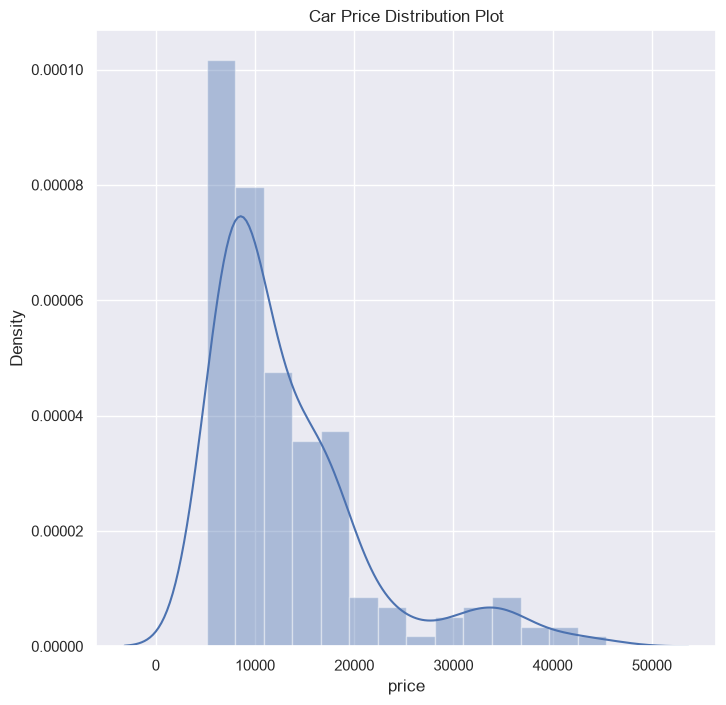

In [11]:
plt.figure(figsize=(8,8))
plt.title('Car Price Distribution Plot')
sns.distplot(df_auto['price'])

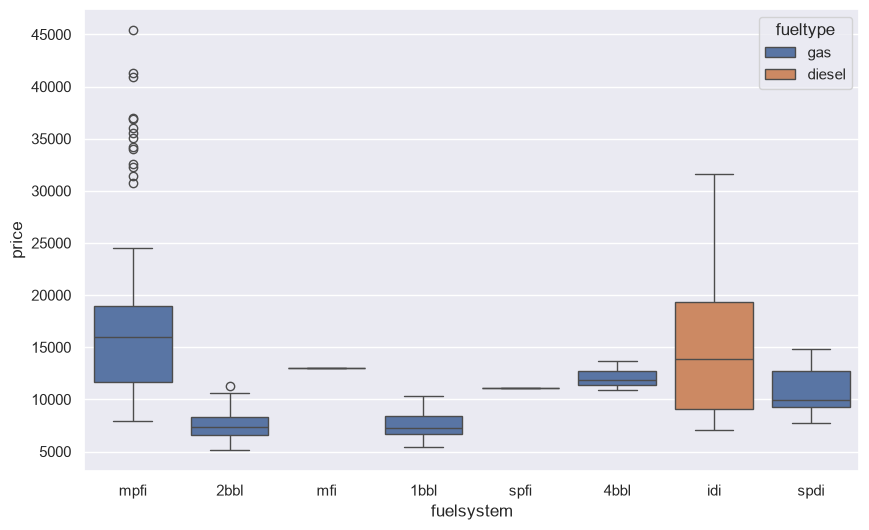

In [12]:
# Relationship between fuelsystem vs price vs fueltype
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'fuelsystem', y = 'price', hue = 'fueltype', data = df_auto)
plt.show()

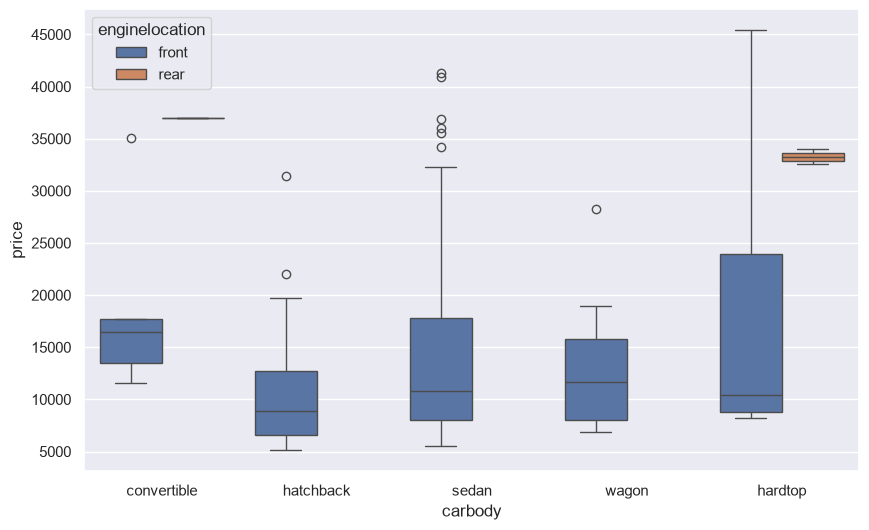

In [13]:
# Relationship between carbody vs price with hue enginelocation
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'carbody', y = 'price', hue = 'enginelocation', data = df_auto)
plt.show()

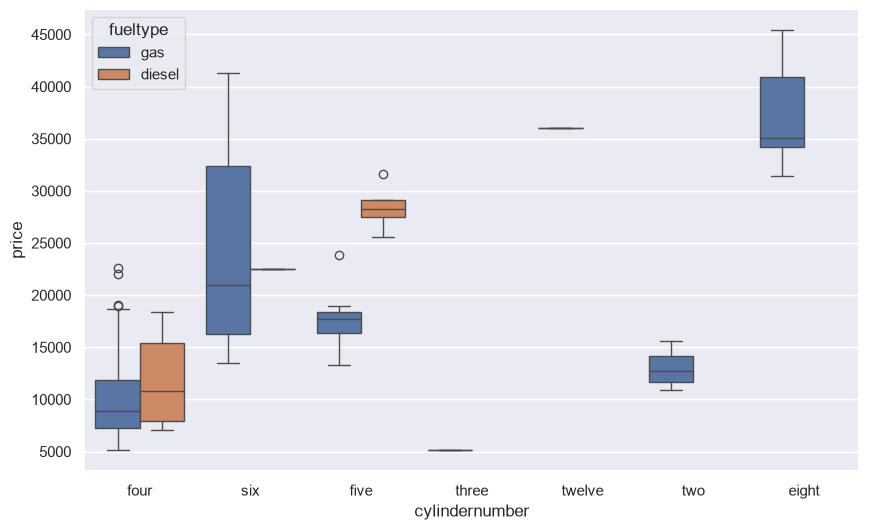

In [14]:
# Relationship between cylindernumber vs price with hue fueltype
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'cylindernumber', y = 'price', hue = 'fueltype', data = df_auto)
plt.show()

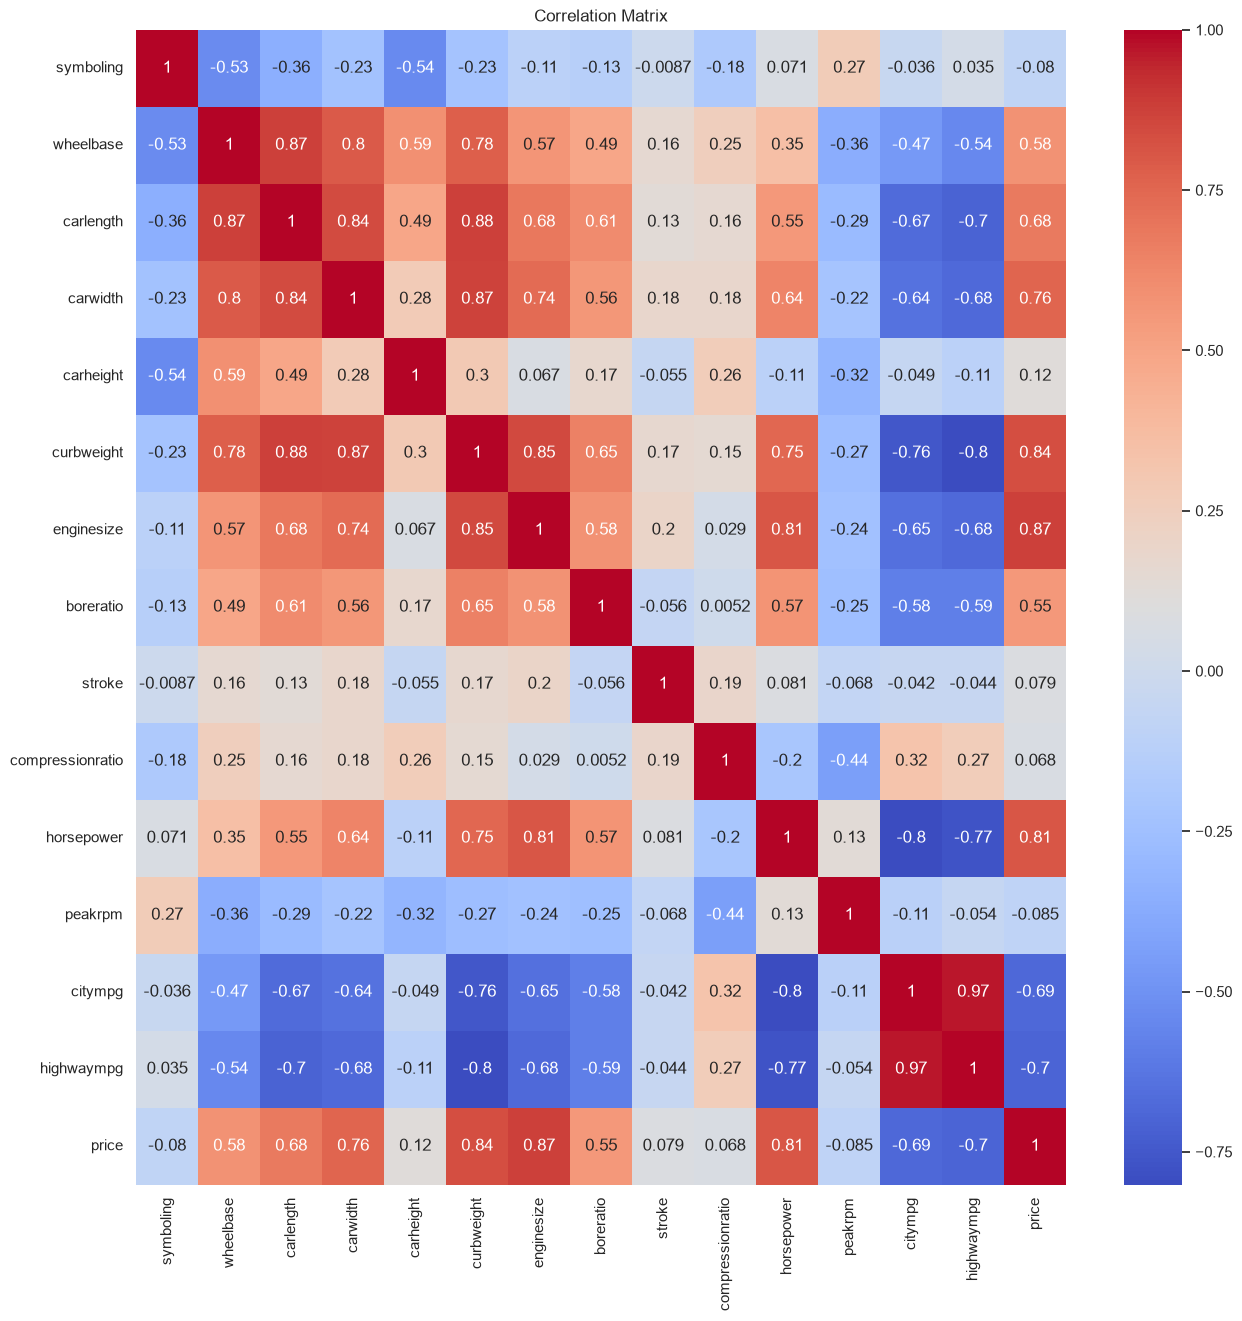

In [15]:
plt.figure(figsize=(15,15))
sns.heatmap(df_auto[num_col].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

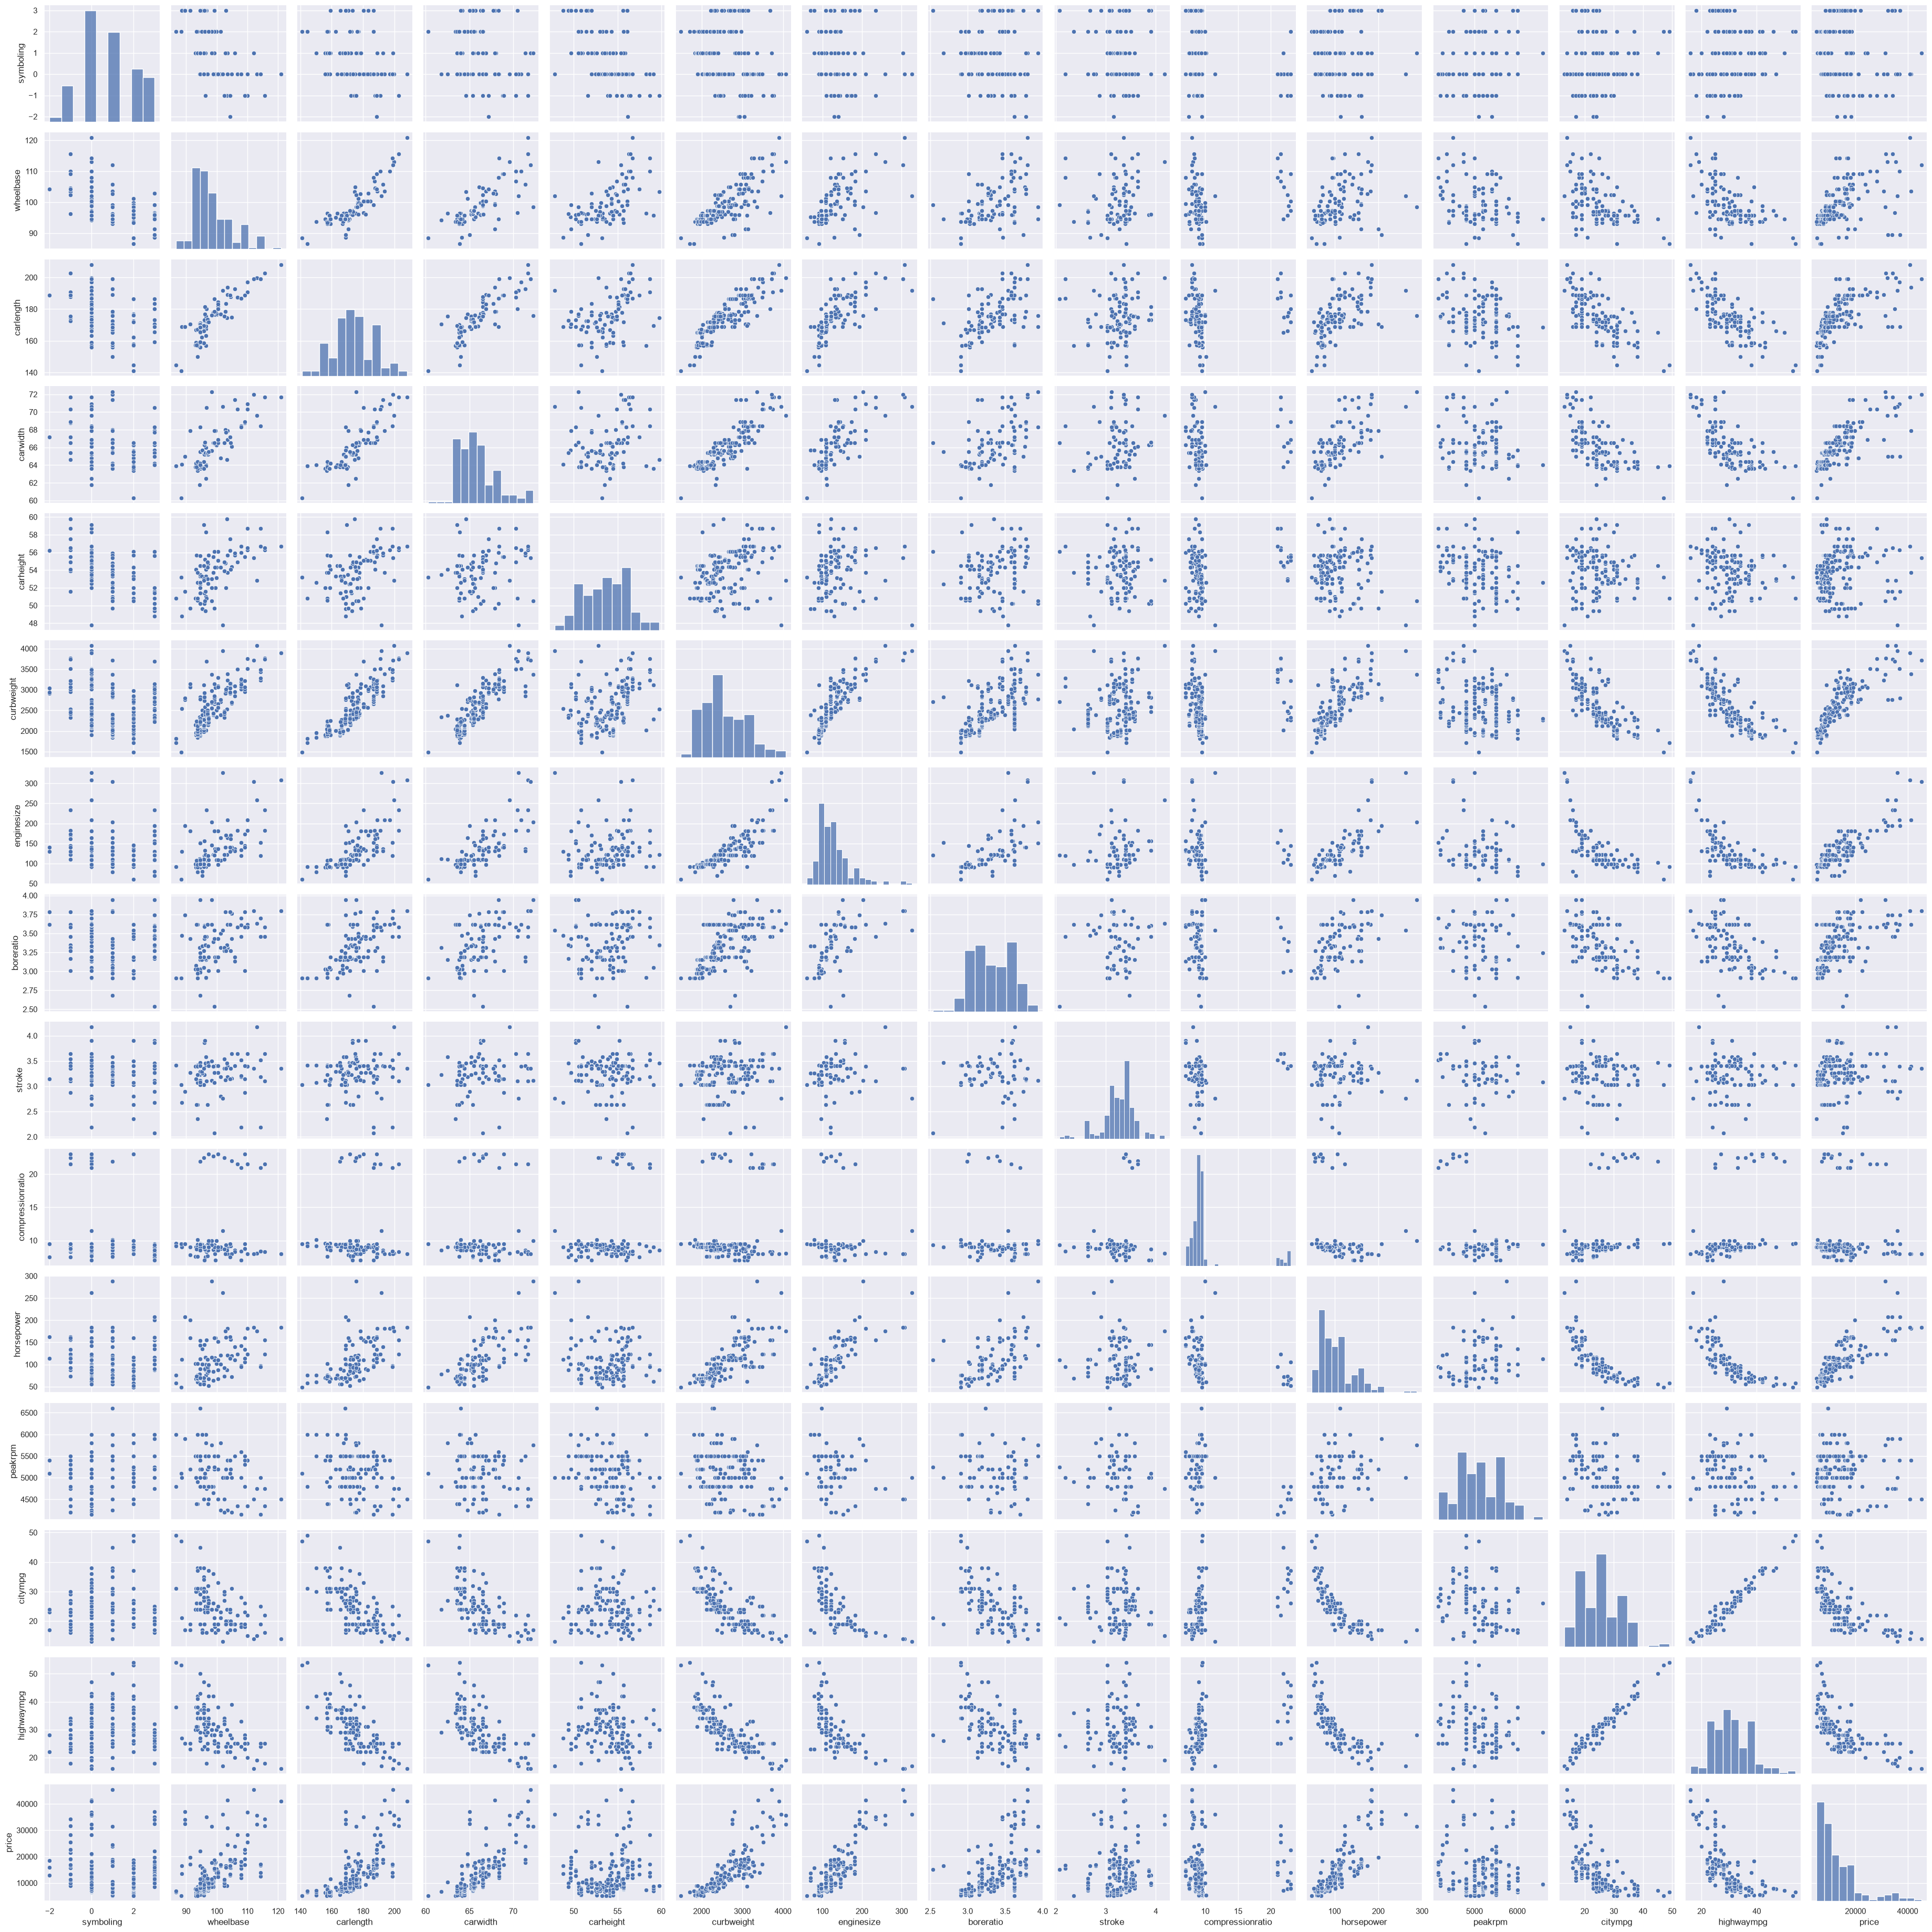

In [16]:
ax = sns.pairplot(df_auto[num_col])

In [17]:
dz=df_auto[['curbweight', 'enginesize', 'horsepower']]
dz.corr()

,curbweight,enginesize,horsepower
curbweight,1.0000,0.8506,0.7507
enginesize,0.8506,1.0000,0.8098
horsepower,0.7507,0.8098,1.0000


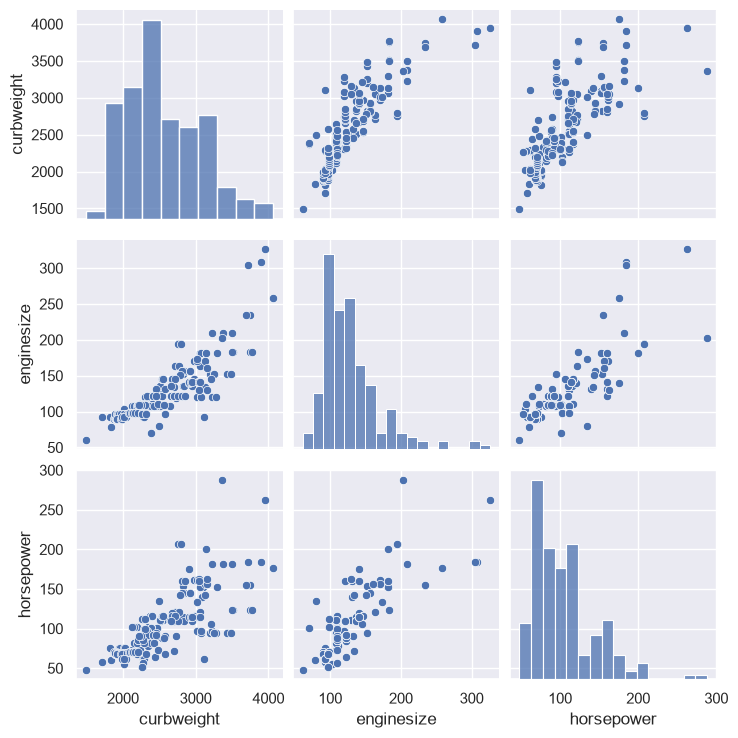

In [18]:
sns.pairplot(dz)

# Building a Multiple Linear Model

## Model 1

In [19]:
X_1 = df_auto[['horsepower']]

In [20]:
X1_C = sm.add_constant(X_1)

In [21]:
Y = df_auto['price']

In [22]:
mlr1 = sm.OLS(Y,X1_C).fit()

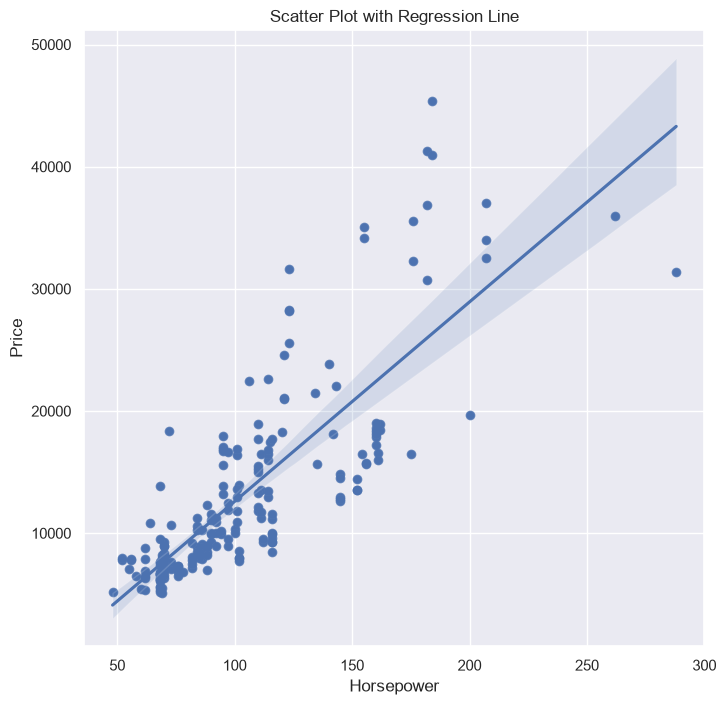

In [23]:
sns.scatterplot(x='horsepower', y='price', data=df_auto)
sns.regplot(x='horsepower', y='price', data=df_auto)
plt.title('Scatter Plot with Regression Line')
plt.xlabel('Horsepower')
plt.ylabel('Price')
plt.show()

In [24]:
print(mlr1.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.653
Model:                            OLS   Adj. R-squared:                  0.651
Method:                 Least Squares   F-statistic:                     382.2
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           1.48e-48
Time:                        20:50:30   Log-Likelihood:                -2024.0
No. Observations:                 205   AIC:                             4052.
Df Residuals:                     203   BIC:                             4059.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3721.7615    929.849     -4.003      0.0

## Model 2

In [25]:
X_2 = df_auto[['curbweight', 'enginesize']]

In [26]:
X2_C = sm.add_constant(X_2)

In [27]:
mlr2 = sm.OLS(Y,X2_C).fit()

In [28]:
print(mlr2.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.793
Method:                 Least Squares   F-statistic:                     390.7
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           3.77e-70
Time:                        20:50:30   Log-Likelihood:                -1970.2
No. Observations:                 205   AIC:                             3946.
Df Residuals:                     202   BIC:                             3956.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.415e+04   1387.924    -10.192      0.0

## Model 3

In [29]:
X = df_auto[['horsepower', 'curbweight', 'enginesize']]

In [30]:
X_C = sm.add_constant(X)

In [31]:
mlr = sm.OLS(Y,X_C).fit()

In [32]:
print(mlr.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     292.9
Date:                Sun, 27 Sep 2026   Prob (F-statistic):           4.36e-73
Time:                        20:50:30   Log-Likelihood:                -1960.2
No. Observations:                 205   AIC:                             3928.
Df Residuals:                     201   BIC:                             3942.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.346e+04   1333.051    -10.100      0.0

# Residual Analysis

In [33]:
# Residual Analysis of the model

# Linearity: Check if the relation between dependent and independent variables is linear
Y_pred = mlr.predict(X_C)
residual = Y - Y_pred
residual

0      -347.4903
1      2657.5097
2     -2478.1760
3      3228.1056
4      1726.7786
         ...    
200     200.5211
201    -255.3203
202     893.6747
203    4746.4045
204    5511.6405
Length: 205, dtype: float64

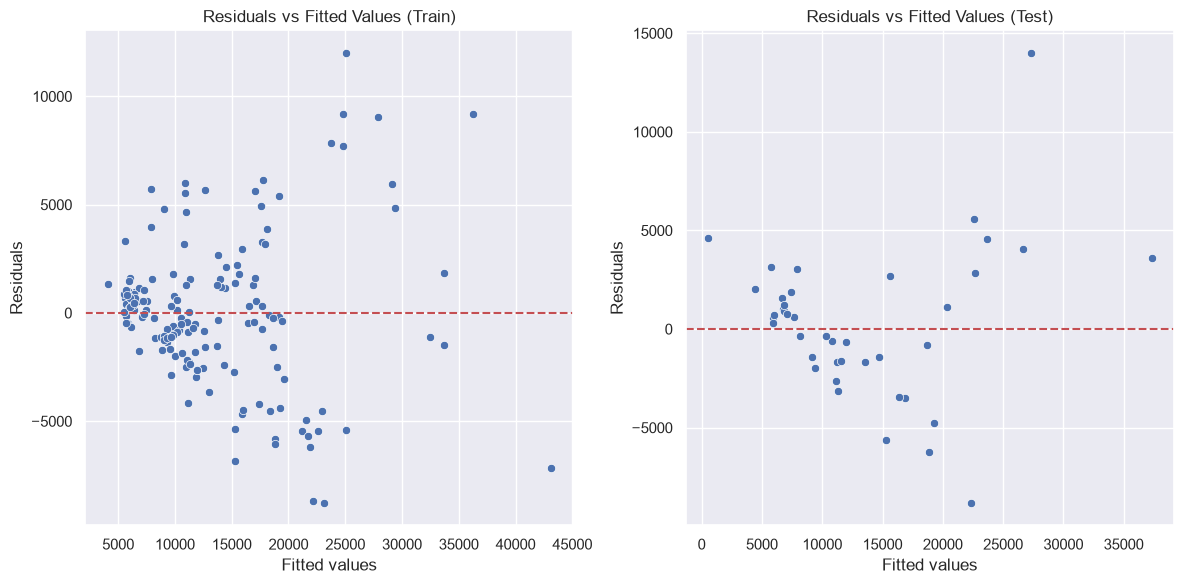

In [34]:
# Selecting relevant features for the model
features = ['curbweight', 'enginesize', 'horsepower']

X = df_auto[features]
y = df_auto['price']

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fitting the linear regression model
lm = LinearRegression()
lm.fit(X_train, y_train)

# Predicting the values
y_train_pred = lm.predict(X_train)
y_test_pred = lm.predict(X_test)

# Calculating residuals
train_residuals = y_train - y_train_pred
test_residuals = y_test - y_test_pred

# Plotting residuals vs. fitted values
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_train_pred, y=train_residuals)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values (Train)')

plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test_pred, y=test_residuals)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values (Test)')
plt.tight_layout()
plt.show()

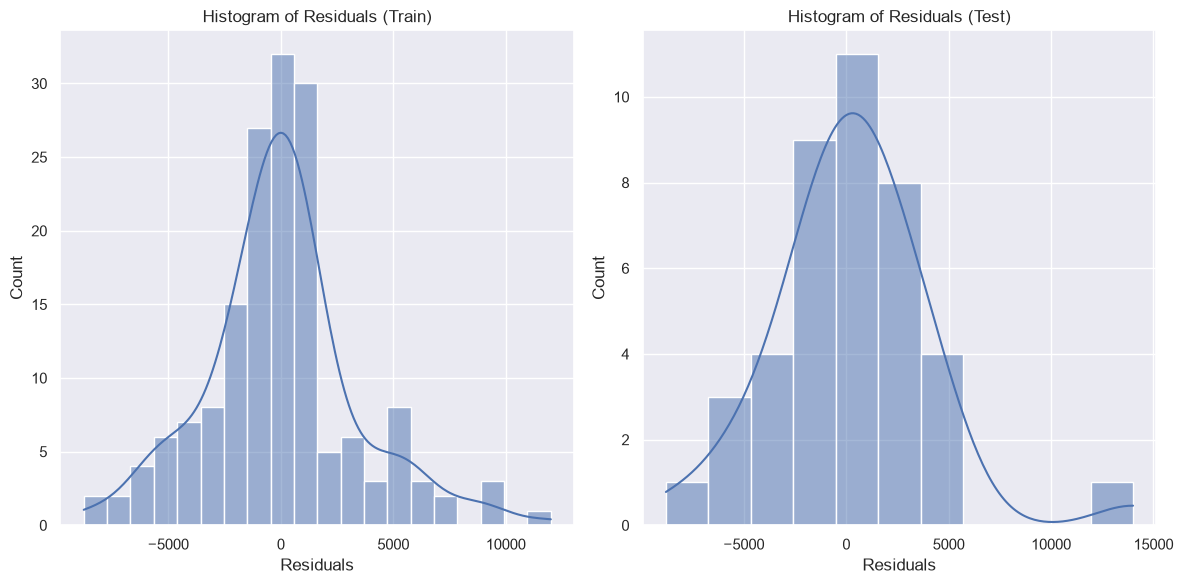

In [35]:
# Histogram of residuals
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(train_residuals, kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals (Train)')

plt.subplot(1, 2, 2)
sns.histplot(test_residuals, kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals (Test)')
plt.tight_layout()
plt.show()

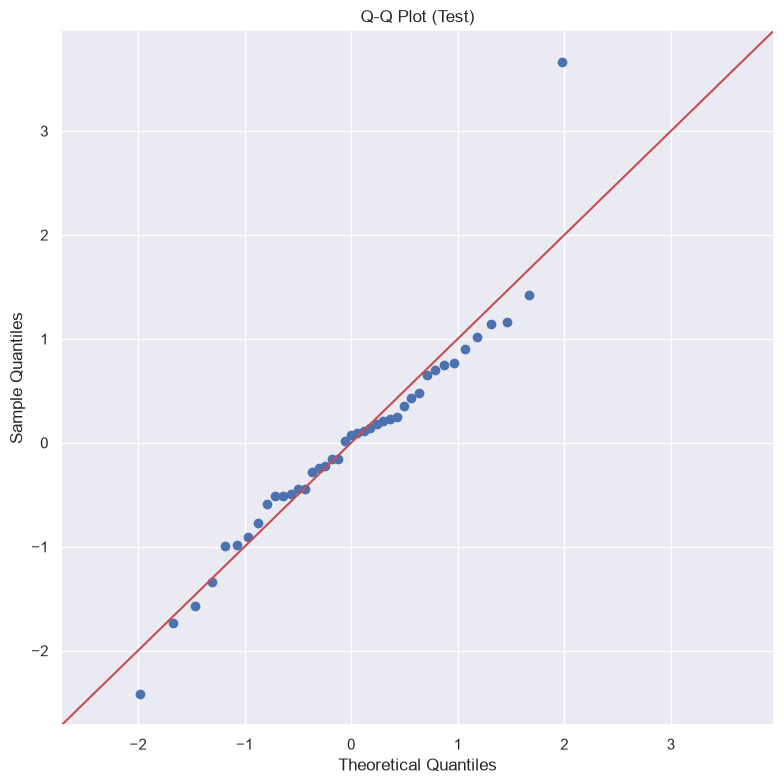

In [36]:
# Q-Q plot for residuals|

sm.qqplot(test_residuals, line='45', fit=True)
plt.title('Q-Q Plot (Test)')
plt.tight_layout()
plt.show()